# EZIE Inversion Example

This notebook provides examples of how to use `SECSpy.EZIE_inversion.inversion`, which enables straightforward ground magnetometer inversions using an EZIE satellite pass.

The steps are:

1. configure an EZIE event and output folder,
2. create the cubed-sphere grids,
3. create the SECS basis,
4. download SuperMAG data,
5. plot the pass with the SECS grid and magnetometers on a polar plot,
6. run the inversion,
7. create PNGs and a video for a chosen time series during the EZIE satellite pass,
8. save and reload state for easy replotting and tweaking of previous inversions.

The default path uses a saved EZIE file in `Data/2025_05_04_07_22_00`.

## Setup

The inversion requires an EZIE file to begin setup. Here we provide an L2 file, an event time (`2025-05-18T23:50:00`), and an `event_time_buffer`. This first step initializes key components and calculates the satellite pass vector, along with the longitude and latitude used for the SECS grid center based on beam 1. The `event_time_buffer` shifts the grid along the satellite pass by moving it before or after `event_time`, which is useful for tweaking.

Creating the inversion object also creates an inversion folder. By default this is `self.inversion_repo = f'./Inversions/{date2filename(event_time)}/'`. Saved outputs, including plots and saved states, are placed in this folder.

In [ ]:
from SECSpy.EZIE_inversion import inversion
import numpy as np
inv= inversion('../Data/ezie_l2_20250518_234515_sva_v001_r001.nc4',
               np.datetime64('2025-05-18T23:50:00'), event_time_buffer=np.timedelta64(35, 's'), inversion_repo='./Inversions/2025_05_18_23_50_00/')

## Create Grid

Here we create the cubed-sphere grids for both the SECS amplitudes and evaluation of estimates. One key option is `auto_center`. Some automatically generated grids have nodes too close to the geographic pole, which the cubed-sphere projection cannot handle. Using `auto_center=True` shifts the grid by small amounts until it is viable. If this is turned off, it is up to the user to provide the grid tweaks necessary, and grid issues will be clearly printed.

In [14]:
inv.create_grid(auto_center=True)

Adjusted grid center to avoid secsy local2geo_enu_rotation assertion.
secsy failed while converting the cubed-sphere grid derivatives to geographic east/north.
The grid/projection is internally inconsistent for local2geo_enu_rotation().
grid shape: (32, 32), size: 1024
EZIE center lon/lat: -0.666498064994812, 69.28919219970703
grid center lon/lat: -0.666498064994812, 69.28919219970703
satellite heading: [ 0.91286531 -0.40826086]
geo lon range: -168.758 to 160.222
geo lat range: 41.7419 to 89.551
local lon range: -178.068 to 178.391
local lat range: 61.5462 to 89.1335
max vertical/east-north residual: 1.42822e-06
failing grid points: 1
  index 969: local lon/lat=(-156.312, 68.8645), geo lon/lat=(160.222, 89.5509), residual=1.42822e-06
Try recreating the grid with auto_center=True, a manual center_shift, smaller L/W, or magnetic_north=True before run_inversion().
Using center_shift=(0.25, 0.0) instead of (0, 0).


## Create Spherical Elementary Current Systems (SECS)

This step uses `SECS.py` and sets up the SECS object using defaults of a current altitude of 110 km and the image-current method for accounting for telluric currents with a depth of 500 km.

In [15]:
inv.create_SECS()

## Download Magnetometer Data

We use the SuperMAG API to download data. Data are automatically selected based on the grid. An optional buffer argument allows the inclusion of magnetometers a percentage outside the grid.

`download_data` also checks magnetometer availability over the downloaded period. Magnetometers that do not have the maximum availability are flagged. With `auto_remove=True`, these magnetometers are removed from the dataset. Alternatively, with `auto_remove=False`, the user can decide which stations to remove.

A username must be provided, so please ensure you have a SuperMAG account.

In [ ]:
inv.download_data('username', auto_remove=True)

stations:  <StringArray>
['MEK', 'ALE', 'LRV', 'LOV', 'LER', 'VAL', 'HAD', 'ESK', 'MAB', 'DOU',
 ...
 'NR2', 'SKD', 'BEY', 'KHS', 'KLI', 'MHV', 'NAD', 'WSE', 'TOP', 'JRU']
Length: 134, dtype: str


## Plot Event Pass

In this step we plot the satellite pass, the SECS grid and its center, and the magnetometer locations if the download step has been completed. By default, the plot is saved in the inversion repository.

text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot li

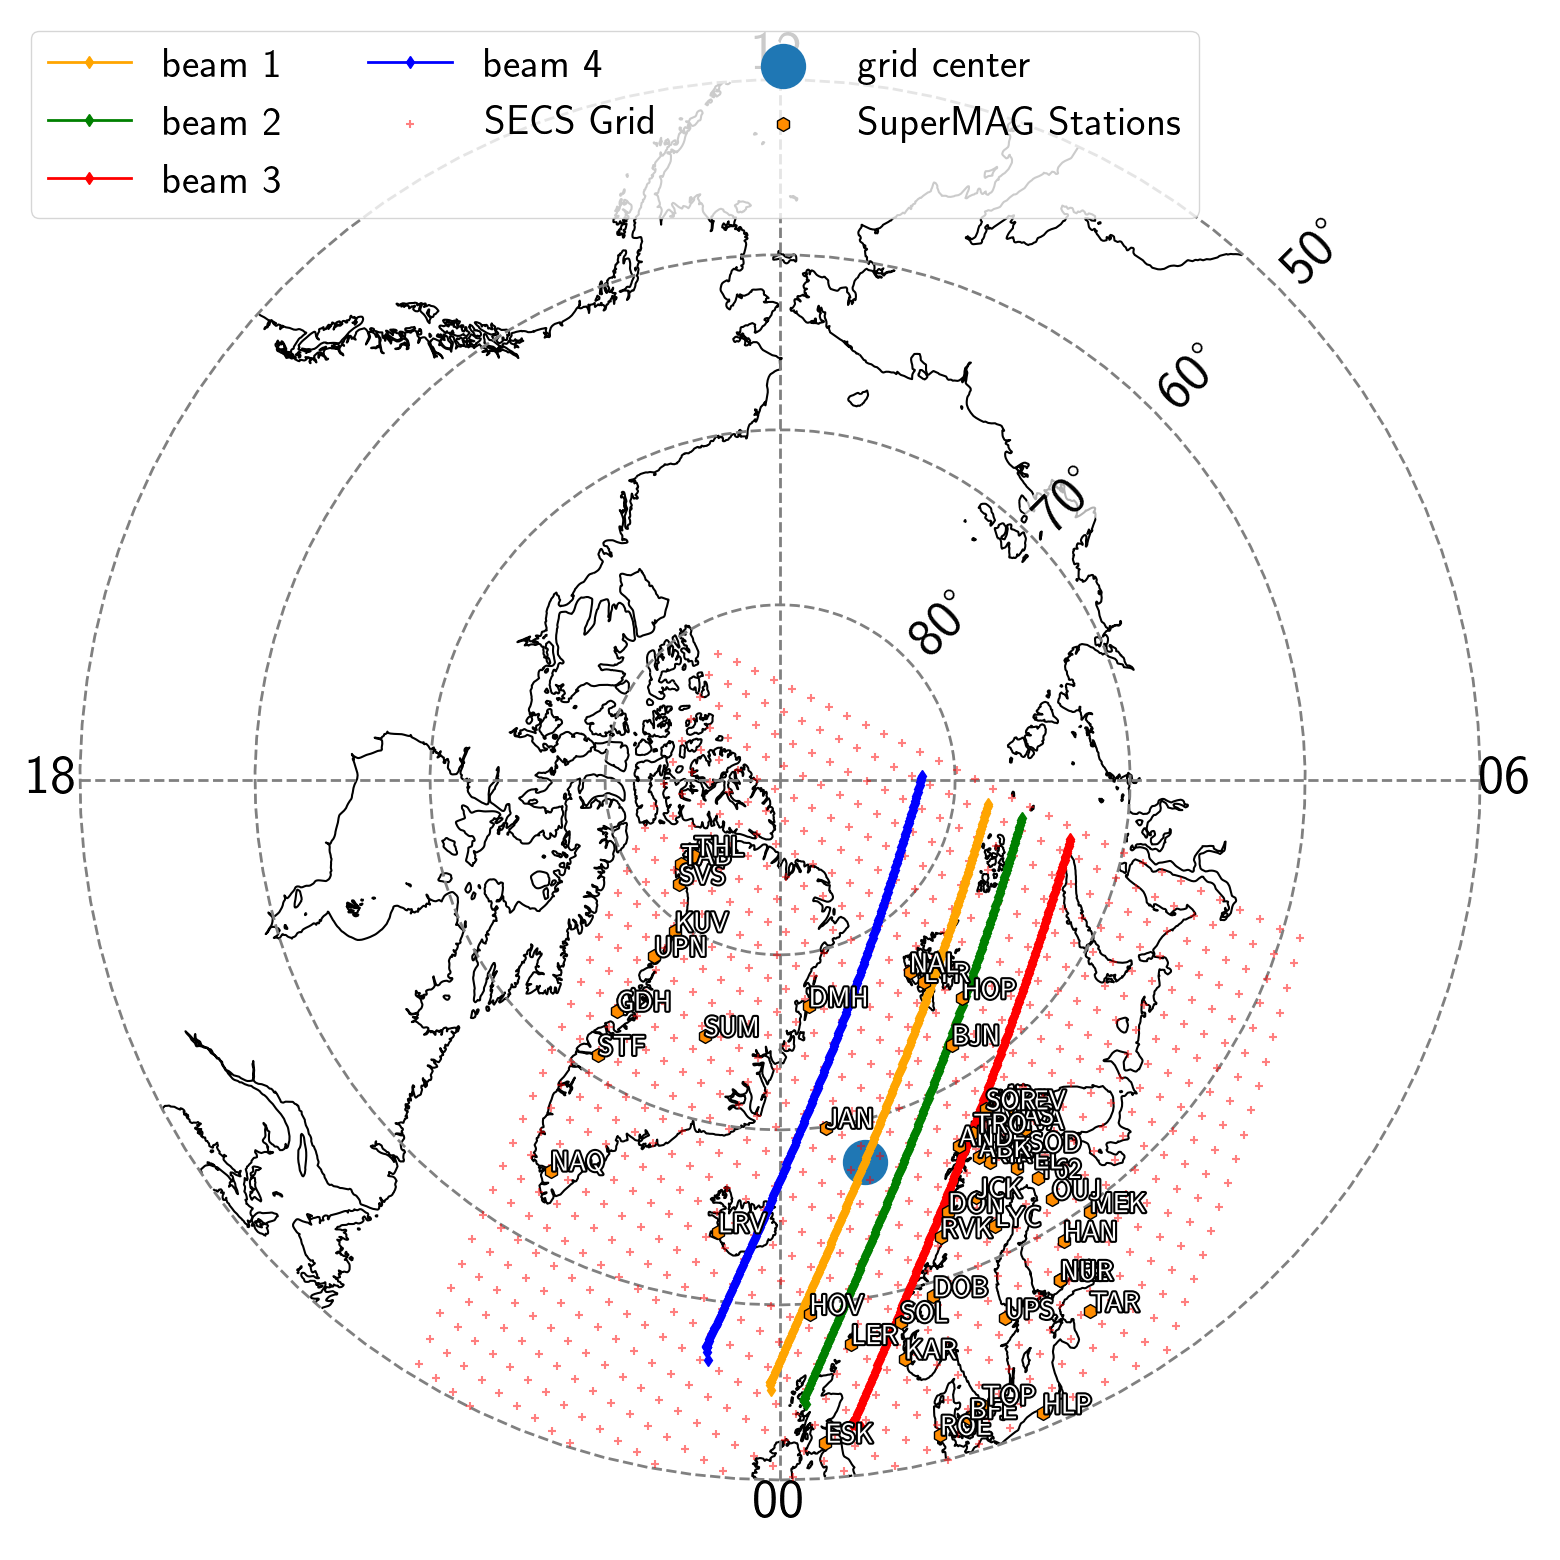

In [17]:
fig= inv.plot_pass(show_site_code=True)

## Run Inversion

This step performs the inversion over the chosen time range and, by default, saves the outputs as xarray netCDF4 files in the inversion repository.

In [18]:
inv.run_inversion()

Running inversion: 100%|██████████| 61/61 [00:01<00:00, 34.08it/s]


('<EZIE_OUTPUT_DIR>/2025_05_18_23_50_00/amps.ncdf4',
 '<EZIE_OUTPUT_DIR>/2025_05_18_23_50_00/estimated.ncdf4')

## Plot Event

This step saves PNGs for each time step across the chosen range of Cartesian plots, and stores them in `cartesian_Event_Plots` in the inversion repository. Important variables to tweak are `Br_lim`, `secs_lim`, and the quiver scales, since these are event specific and depend on the magnitude of the activity.

Plotting event: 100%|██████████| 61/61 [00:56<00:00,  1.08frame/s]


FFmpeg CMD: ffmpeg -hide_banner -stats -y -framerate 5 -start_number 0 -i <EZIE_OUTPUT_DIR>/check_2/2025_05_18_23_50_00/cartesian_Event_Plots/%02d.png -vf scale=3206:1606:flags=lanczos -c:v libx264 -preset veryfast -crf 23 -pix_fmt yuv420p <EZIE_OUTPUT_DIR>/check_2/2025_05_18_23_50_00/cartesian.mp4
Input #0, image2, from '<EZIE_OUTPUT_DIR>/check_2/2025_05_18_23_50_00/cartesian_Event_Plots/%02d.png':
  Duration: 00:00:12.20, start: 0.000000, bitrate: N/A
  Stream #0:0: Video: png, rgba(pc, gbr/unknown/unknown), 3206x1606 [SAR 3937:3937 DAR 1603:803], 5 fps, 5 tbr, 5 tbn
Stream mapping:
  Stream #0:0 -> #0:0 (png (native) -> h264 (libx264))
Press [q] to stop, [?] for help
[libx264 @ 0x569311e29700] using SAR=1/1
[libx264 @ 0x569311e29700] using cpu capabilities: MMX2 SSE2Fast SSSE3 SSE4.2 AVX FMA3 BMI2 AVX2
[libx264 @ 0x569311e29700] profile High, level 5.0, 4:2:0, 8-bit
[libx264 @ 0x569311e29700] 264 - core 164 r3108 31e19f9 - H.264/MPEG-4 AVC codec - Copyleft 2003-2023 - http://www.vid

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

Created GIF: <EZIE_OUTPUT_DIR>/check_2/2025_05_18_23_50_00/cartesian.gif


[out#0/gif @ 0x654b48b01840] video:24688kB audio:0kB subtitle:0kB other streams:0kB global headers:0kB muxing overhead: 0.000079%
frame=   61 fps=2.8 q=-0.0 Lsize=   24688kB time=00:00:12.00 bitrate=16853.6kbits/s speed=0.547x    


'<EZIE_OUTPUT_DIR>/check_2/2025_05_18_23_50_00/cartesian_Event_Plots'

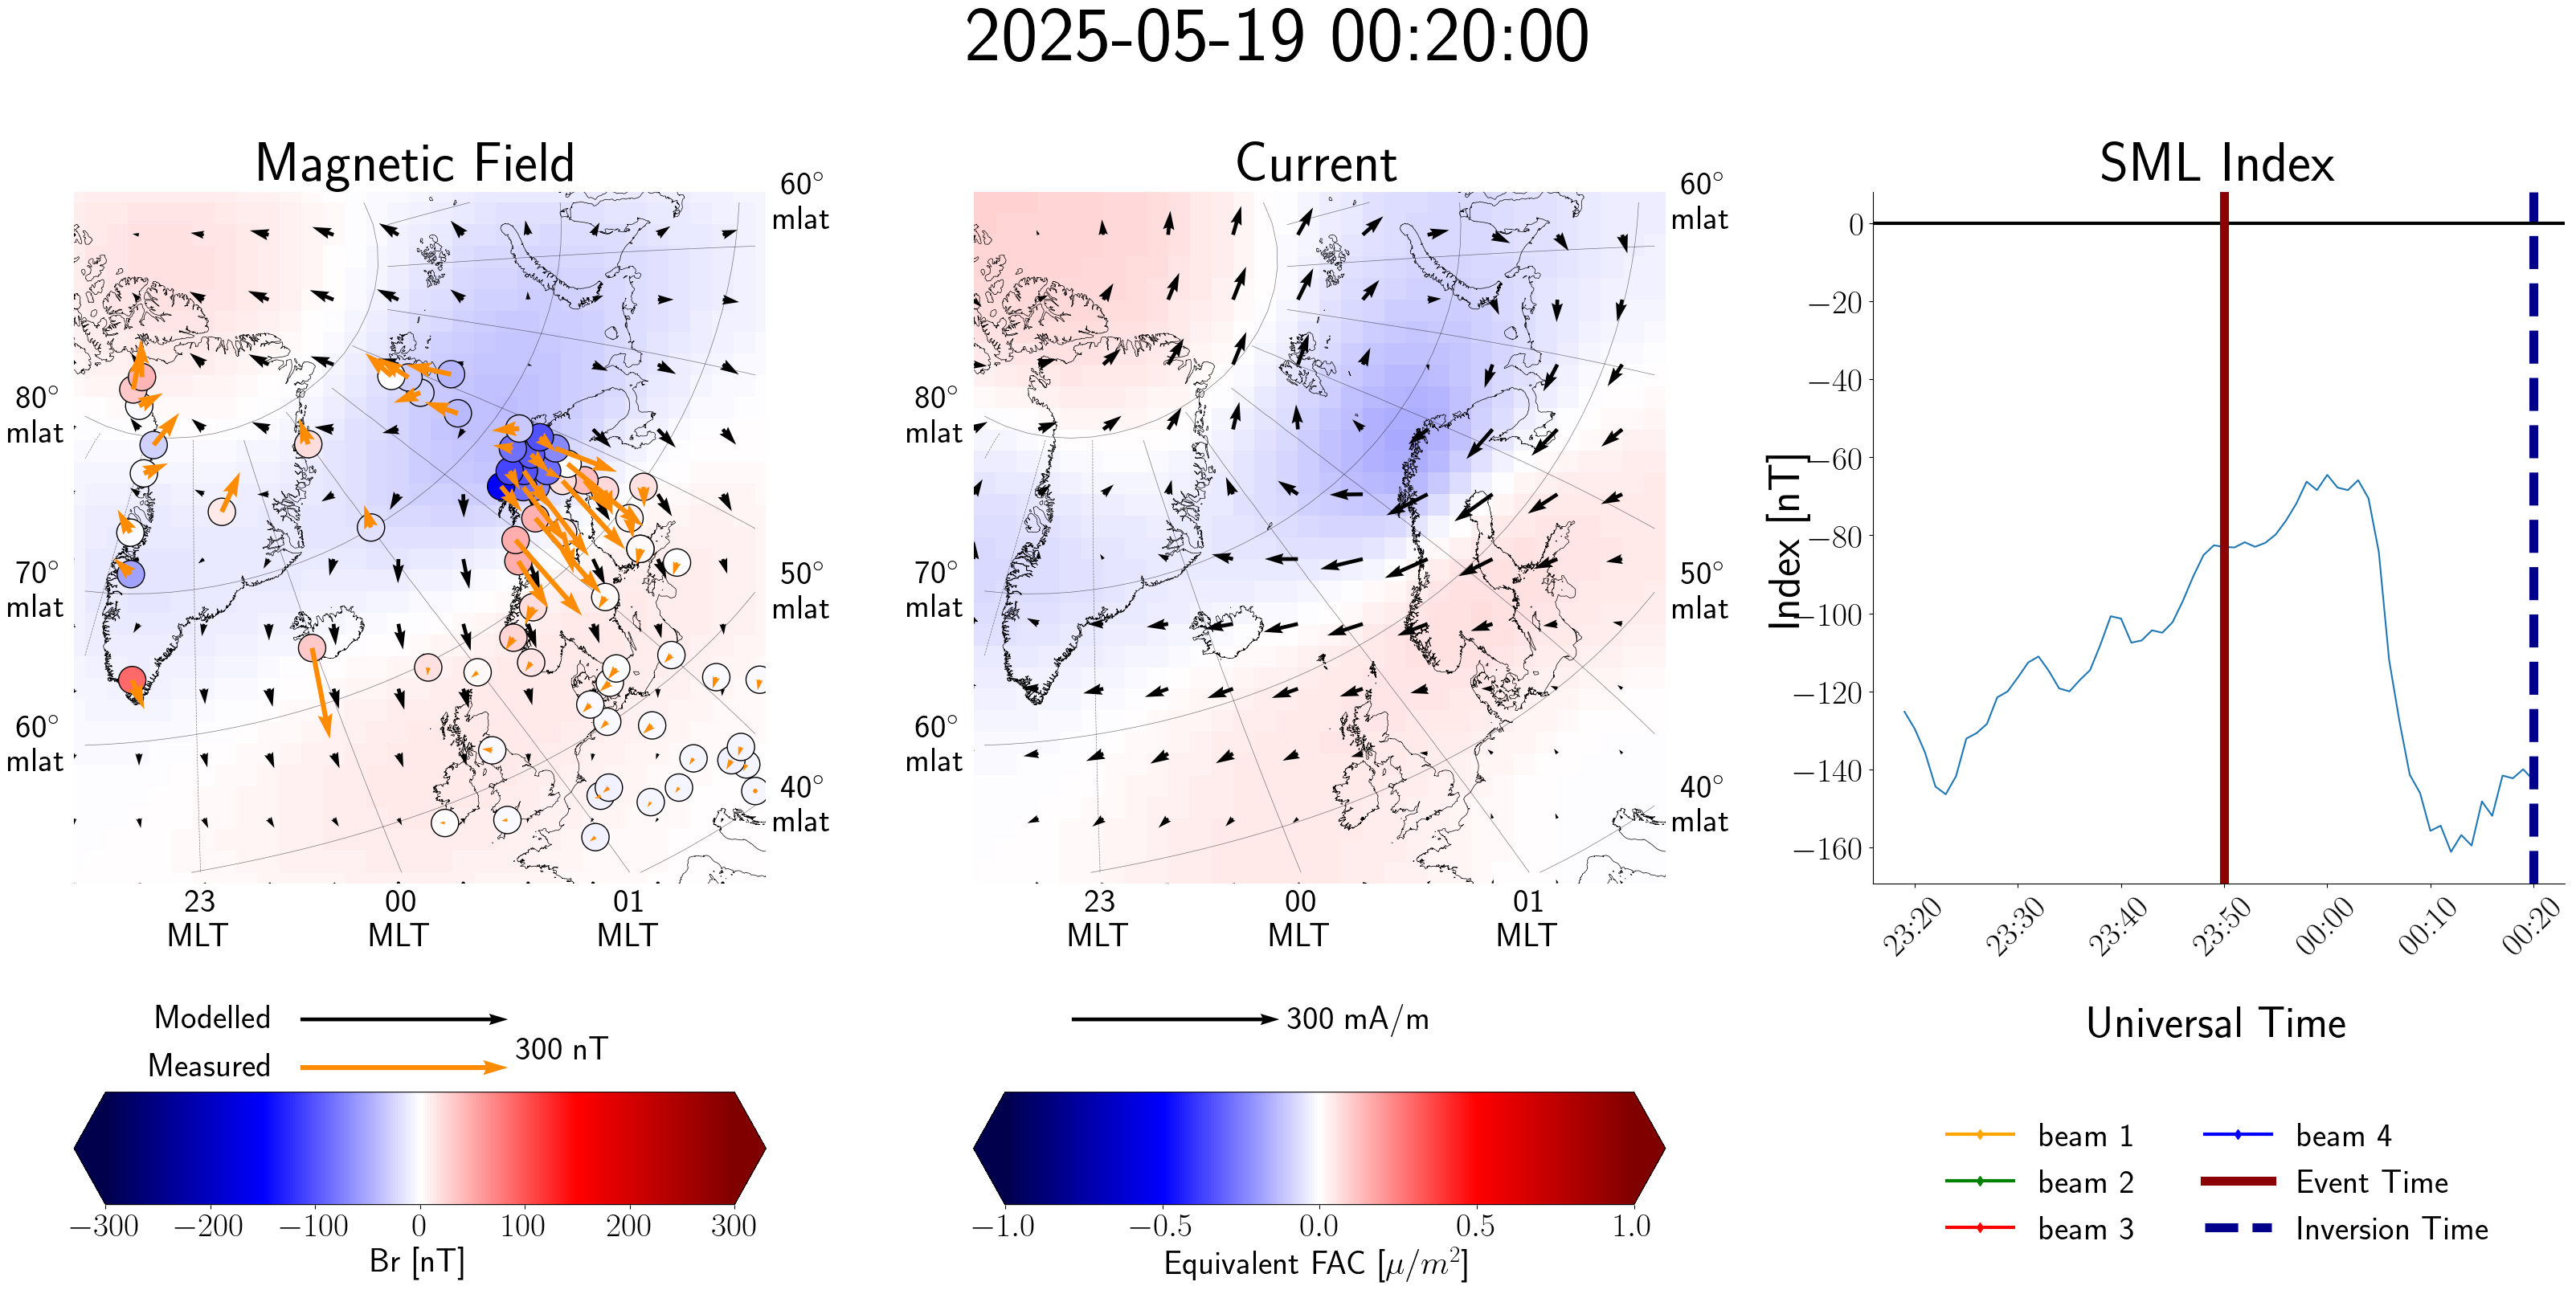

In [23]:
inv.plot_event(mag_quiver_kwargs={'scale': 1e-6, 'zorder': 100},
                mag_quiver_key_kwargs= {'U':300e-9, 'zorder':500, 'fontproperties':{'size':30}},
                mag_scatter_kwargs={'zorder': 120, 's': 600, 'marker':'o', 'edgecolors': 'black'}, 
                current_quiver_kwargs={'scale': 1e0, 'zorder': 100}, 
                current_quiver_key_kwargs={'U':  300e-3, 'zorder':500, 'fontproperties':{'size':30}},
                Br_lim=300, secs_lim=1)

## Save and Load State

We also provide tools to save and reload inversion objects. If one zips the inversion repo then saved states can be transferred easily between users. Saving and loading states allows the user to return to a previous inversion for replotting or parameter tweaking without repeating unchanged steps.

In [ ]:
inv.save_state()
from SECSpy.EZIE_inversion import inversion
inv= inversion.load_state('./Inversions/2025_05_18_23_50_00/inversion_state.json')


## Optional: Run the Full Workflow

`run_all` is the convenience wrapper for the whole process: grids, SECS setup, SuperMAG download, pass plot, inversion, and event plots.

Creating grids...
Creating SECS poles...
stations:  <StringArray>
['MEK', 'ALE', 'LRV', 'LOV', 'LER', 'VAL', 'HAD', 'ESK', 'MAB', 'DOU',
 ...
 'NR2', 'SKD', 'BEY', 'KHS', 'KLI', 'MHV', 'NAD', 'WSE', 'TOP', 'JRU']
Length: 134, dtype: str


Plotting satellite pass...
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to override
text outside plot limit - set "ignore_plot_limits = True" to ov

Running inversion: 100%|██████████| 61/61 [00:01<00:00, 31.96it/s]


Plotting event...


Plotting event: 100%|██████████| 61/61 [00:57<00:00,  1.05frame/s]


FFmpeg CMD: ffmpeg -hide_banner -stats -y -framerate 5 -start_number 0 -i <EZIE_OUTPUT_DIR>/2025_05_18_23_50_00/cartesian_Event_Plots/%02d.png -vf scale=3206:1606:flags=lanczos -c:v libx264 -preset veryfast -crf 23 -pix_fmt yuv420p <EZIE_OUTPUT_DIR>/2025_05_18_23_50_00/cartesian.mp4
Input #0, image2, from '<EZIE_OUTPUT_DIR>/2025_05_18_23_50_00/cartesian_Event_Plots/%02d.png':
  Duration: 00:00:12.20, start: 0.000000, bitrate: N/A
  Stream #0:0: Video: png, rgba(pc, gbr/unknown/unknown), 3206x1606 [SAR 3937:3937 DAR 1603:803], 5 fps, 5 tbr, 5 tbn
Stream mapping:
  Stream #0:0 -> #0:0 (png (native) -> h264 (libx264))
Press [q] to stop, [?] for help
[libx264 @ 0x5aead1f077c0] using SAR=1/1
[libx264 @ 0x5aead1f077c0] using cpu capabilities: MMX2 SSE2Fast SSSE3 SSE4.2 AVX FMA3 BMI2 AVX2
[libx264 @ 0x5aead1f077c0] profile High, level 5.0, 4:2:0, 8-bit
[libx264 @ 0x5aead1f077c0] 264 - core 164 r3108 31e19f9 - H.264/MPEG-4 AVC codec - Copyleft 2003-2023 - http://www.videolan.org/x264.html - op

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

Created GIF: <EZIE_OUTPUT_DIR>/2025_05_18_23_50_00/cartesian.gif


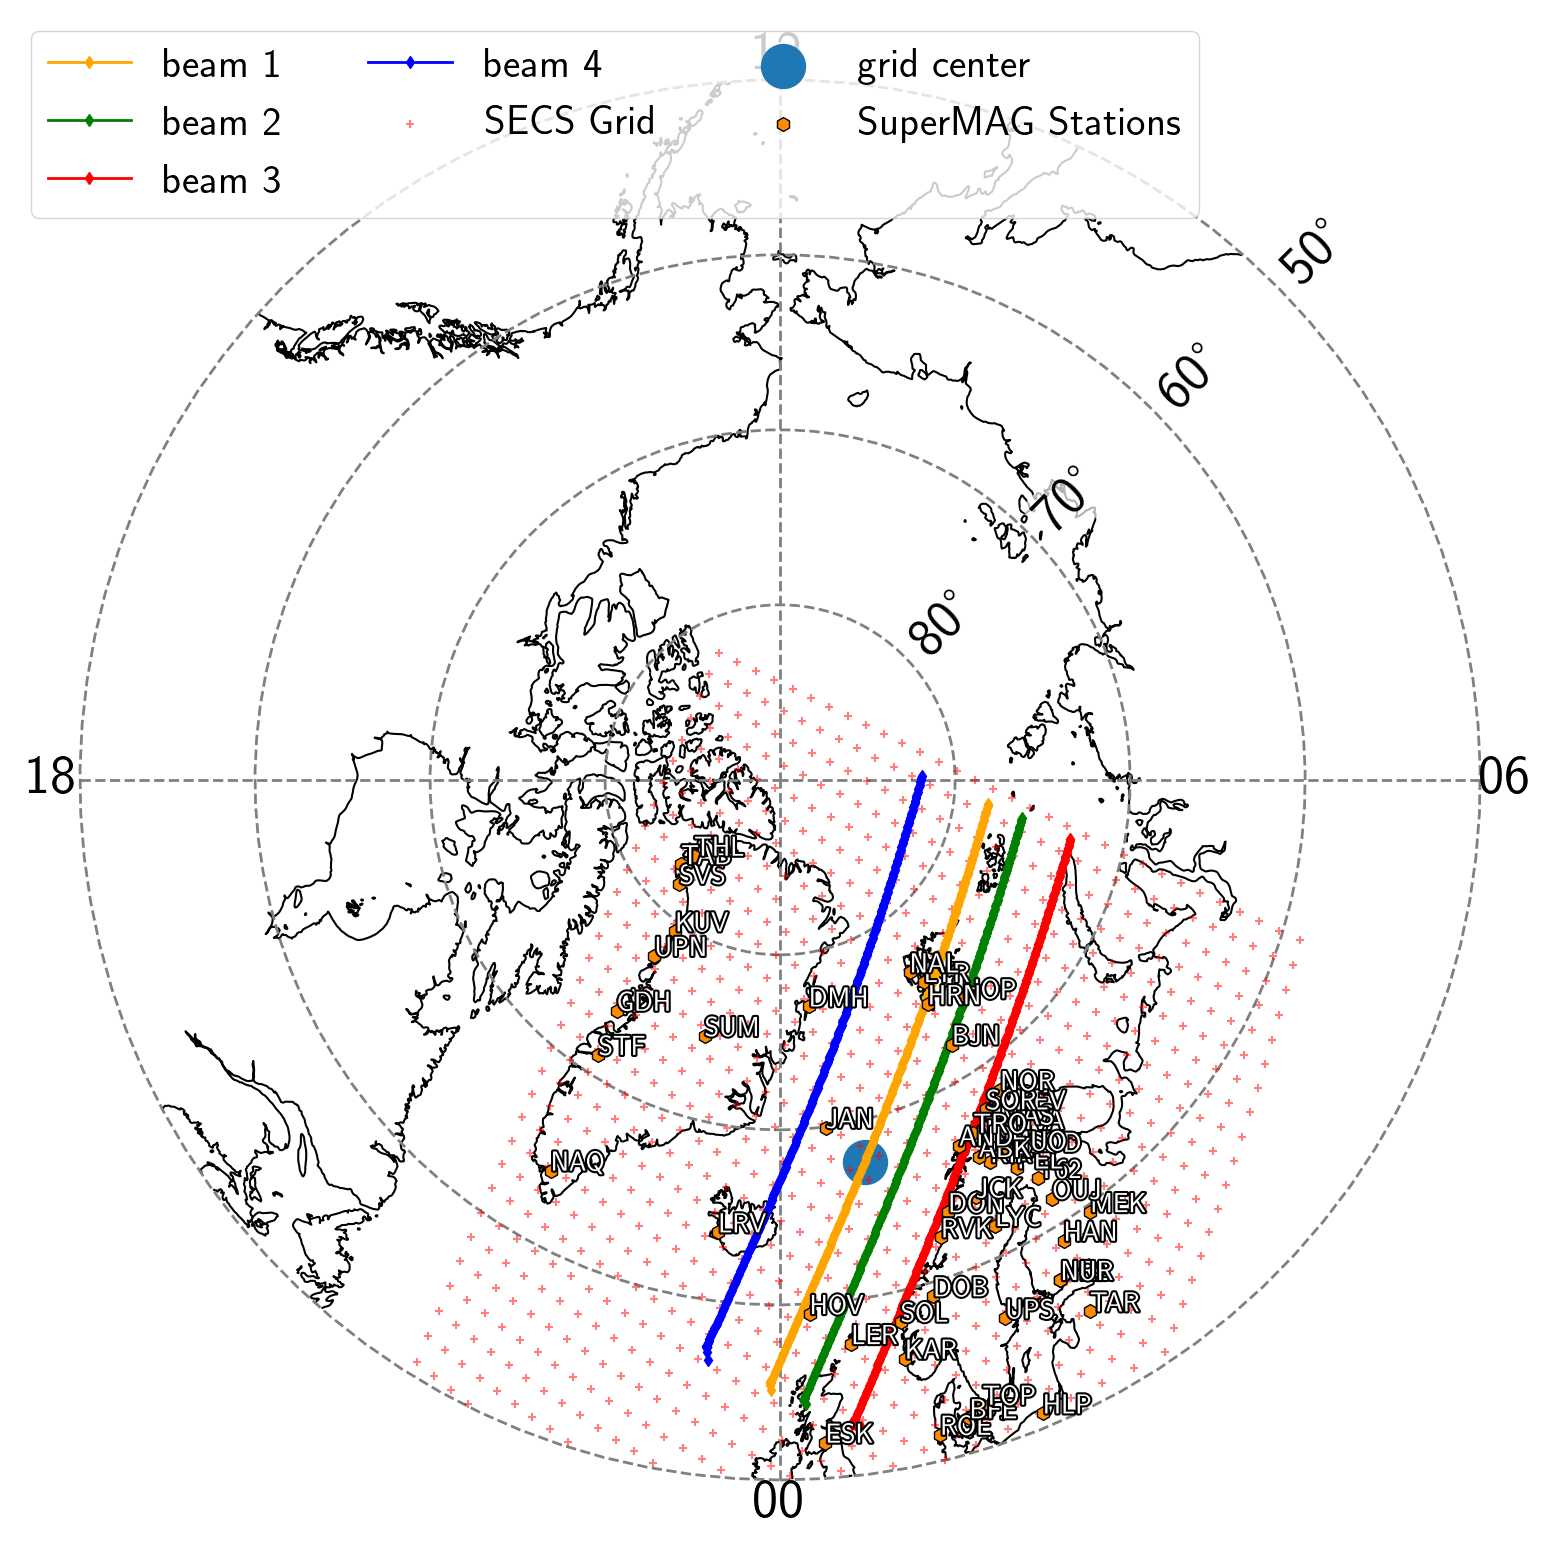

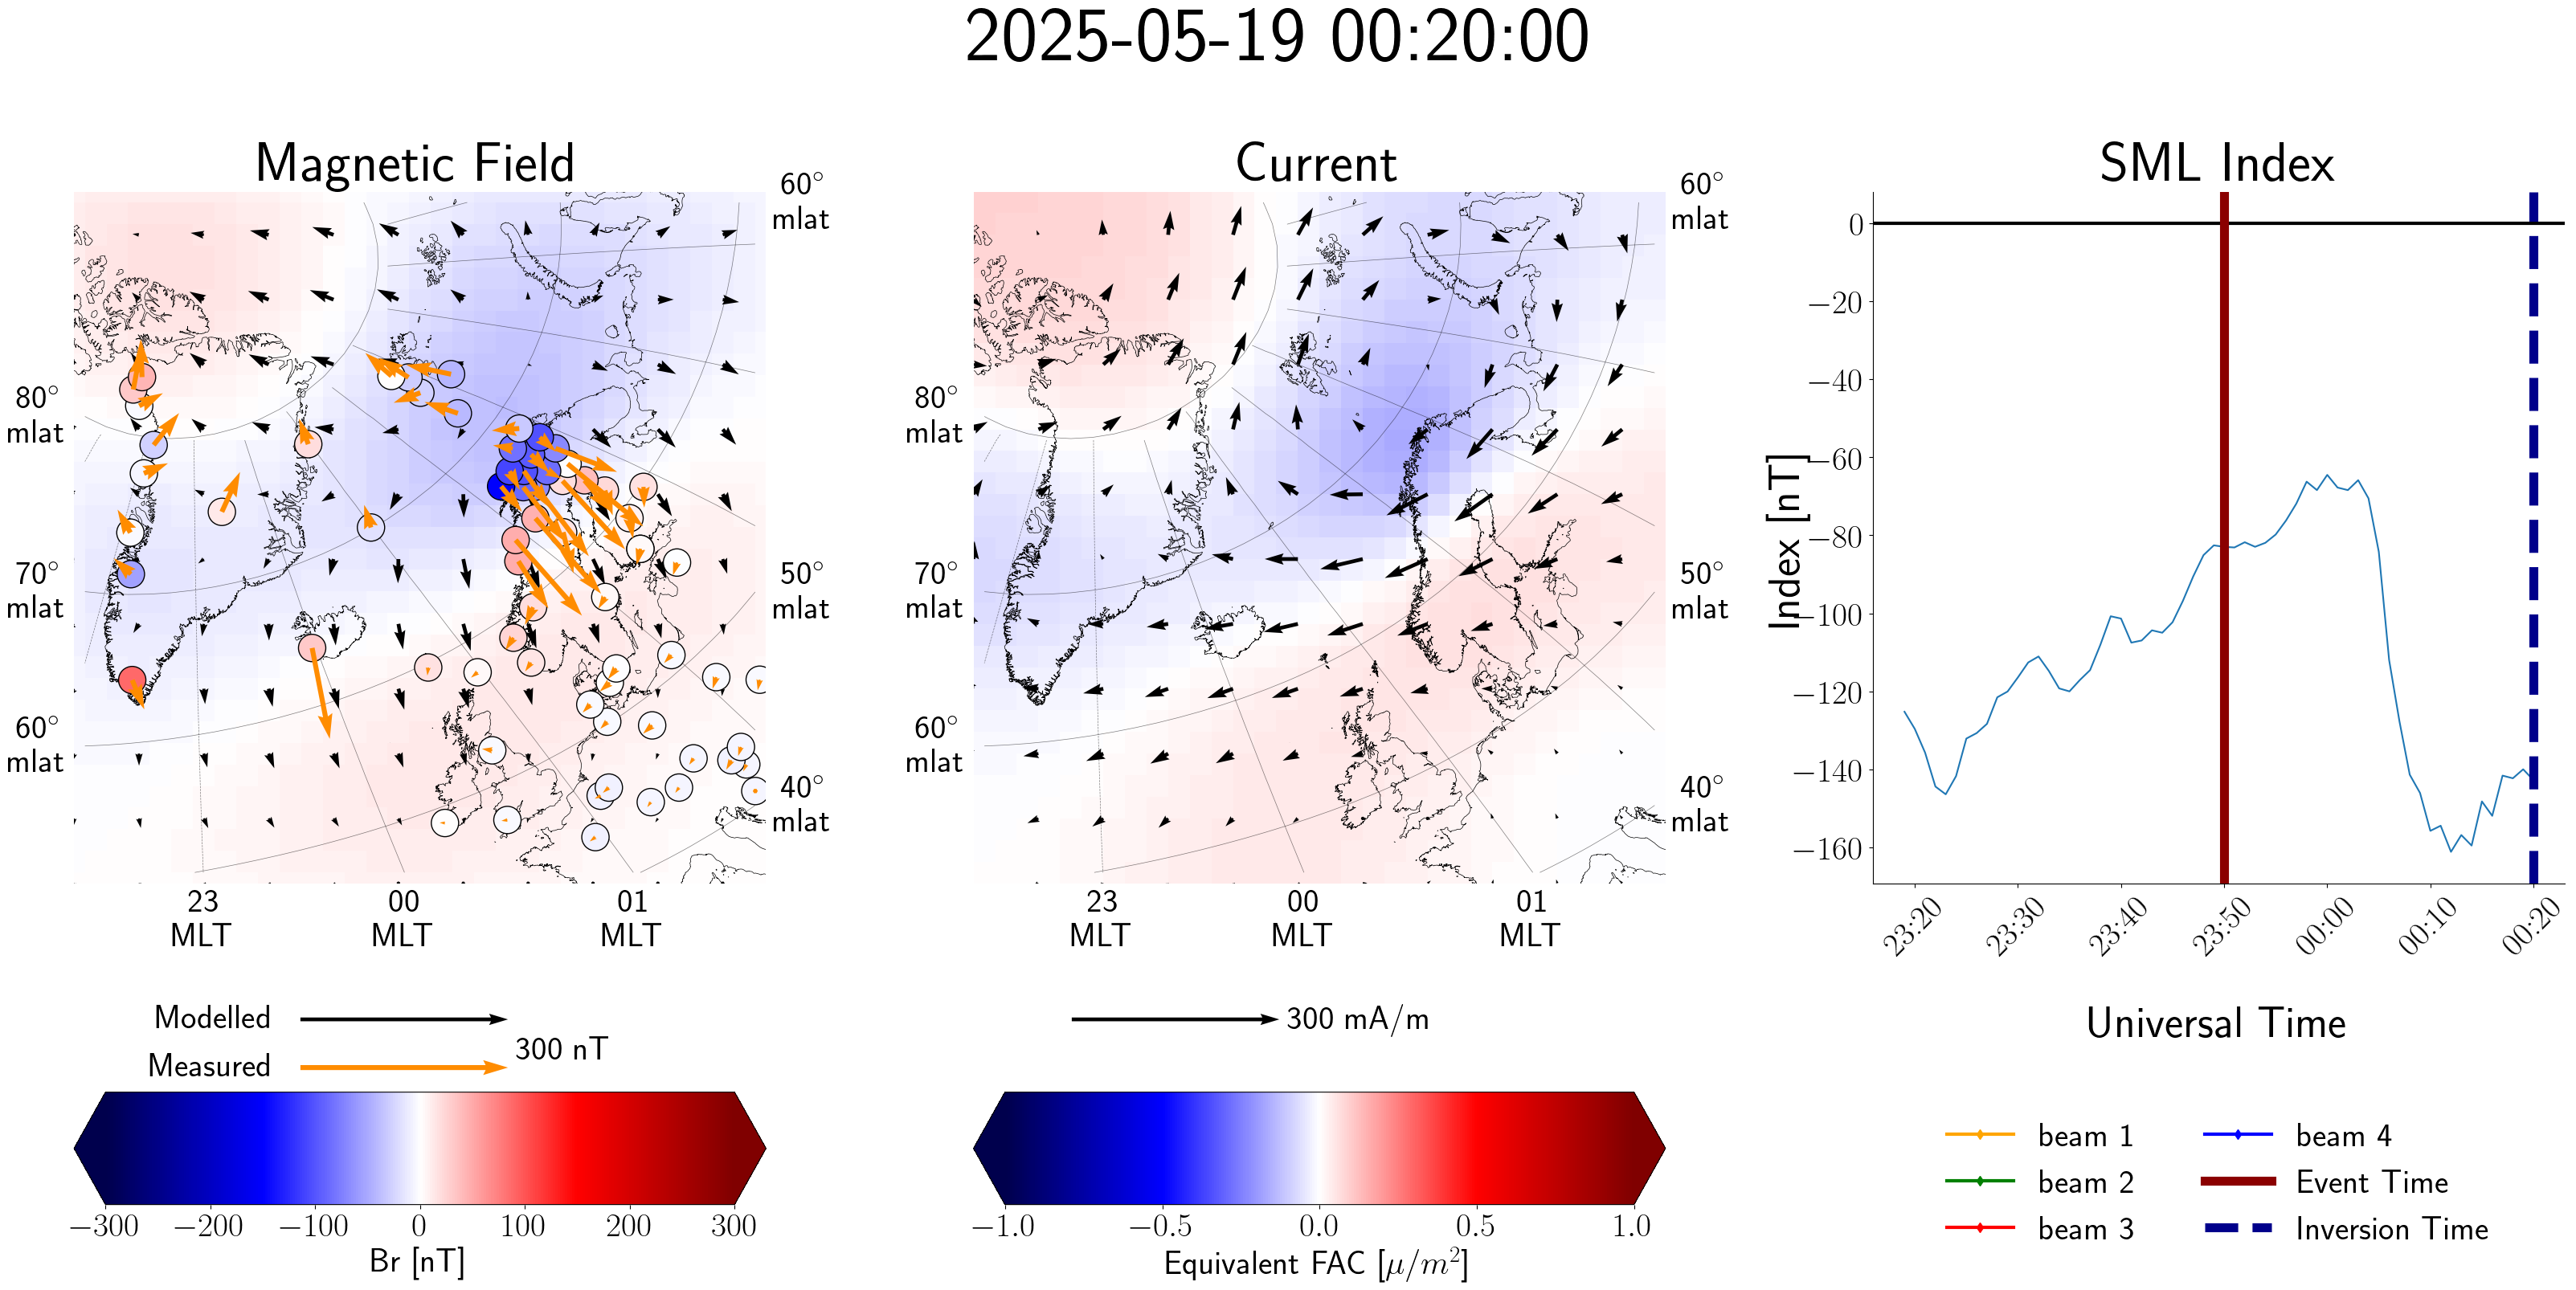

In [ ]:
from SECSpy.EZIE_inversion import inversion
import numpy as np
full_inv = inversion('../Data/ezie_l2_20250518_234515_sva_v001_r001.nc4',
               np.datetime64('2025-05-18T23:50:00'), event_time_buffer=np.timedelta64(35, 's'))
full_inv, output_dir = inv.run_all(
    username='username',
    grid_kwargs={"auto_center": True},
    start=-np.timedelta64(30, "m"),
    end=np.timedelta64(30, "m"),
    l1=3e3,
    l2=6e3,
    plot_start=-np.timedelta64(30, "m"),
    plot_end=np.timedelta64(30, "m"),
    plot_time_step=np.timedelta64(1, "m"),
    verbose=True,
    auto_remove=True,
    plot_kwargs=dict(
    mag_quiver_kwargs={'scale': 1e-6, 'zorder': 100},
    mag_quiver_key_kwargs= {'U':300e-9, 'zorder':500, 'fontproperties':{'size':30}},
    mag_scatter_kwargs={'zorder': 120, 's': 600, 'marker':'o', 'edgecolors': 'black'}, 
    current_quiver_kwargs={'scale': 1e0, 'zorder': 100}, 
    current_quiver_key_kwargs={'U':  300e-3, 'zorder':500, 'fontproperties':{'size':30}},
    Br_lim=300, secs_lim=1)
)